# 04 — Comprehensive 11-Model Benchmarking & Ablation Experiments

All experiments are conducted strictly on the 80% training split (`n=456`) using `RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)`. The holdout test set (`n=114`) is never touched.

=== Experiment 1: 11-Model Baseline Comparison ===


,model,roc_auc_mean,roc_auc_std,pr_auc_mean,f1_score_mean,recall_sensitivity_mean,specificity_mean,balanced_accuracy_mean,brier_score_mean
0,ExtraTrees,0.7343,0.0477,0.8876,0.8186,0.9303,0.1526,0.5414,0.1781
1,KNN,0.7279,0.0455,0.8780,0.8008,0.8574,0.3000,0.5787,0.1818
2,LogisticRegression,0.7228,0.0485,0.8791,0.8143,0.9036,0.2186,0.5611,0.1800
3,RandomForest,0.7211,0.0454,0.8795,0.8065,0.8779,0.2595,0.5687,0.1816
4,CatBoost,0.7074,0.0486,0.8710,0.7945,0.8462,0.2972,0.5717,0.1963
5,GradientBoosting,0.7046,0.0569,0.8673,0.7998,0.8482,0.3255,0.5868,0.1961
6,XGBoost,0.7015,0.0539,0.8685,0.7854,0.8226,0.3251,0.5738,0.2043
7,HistGradientBoosting,0.6991,0.0528,0.8688,0.7810,0.8236,0.2951,0.5593,0.2008
8,LightGBM,0.6988,0.0466,0.8697,0.7888,0.8246,0.3406,0.5826,0.2258
9,SVM_RBF,0.6348,0.0501,0.8119,0.8322,1.0000,0.0000,0.5000,0.2013


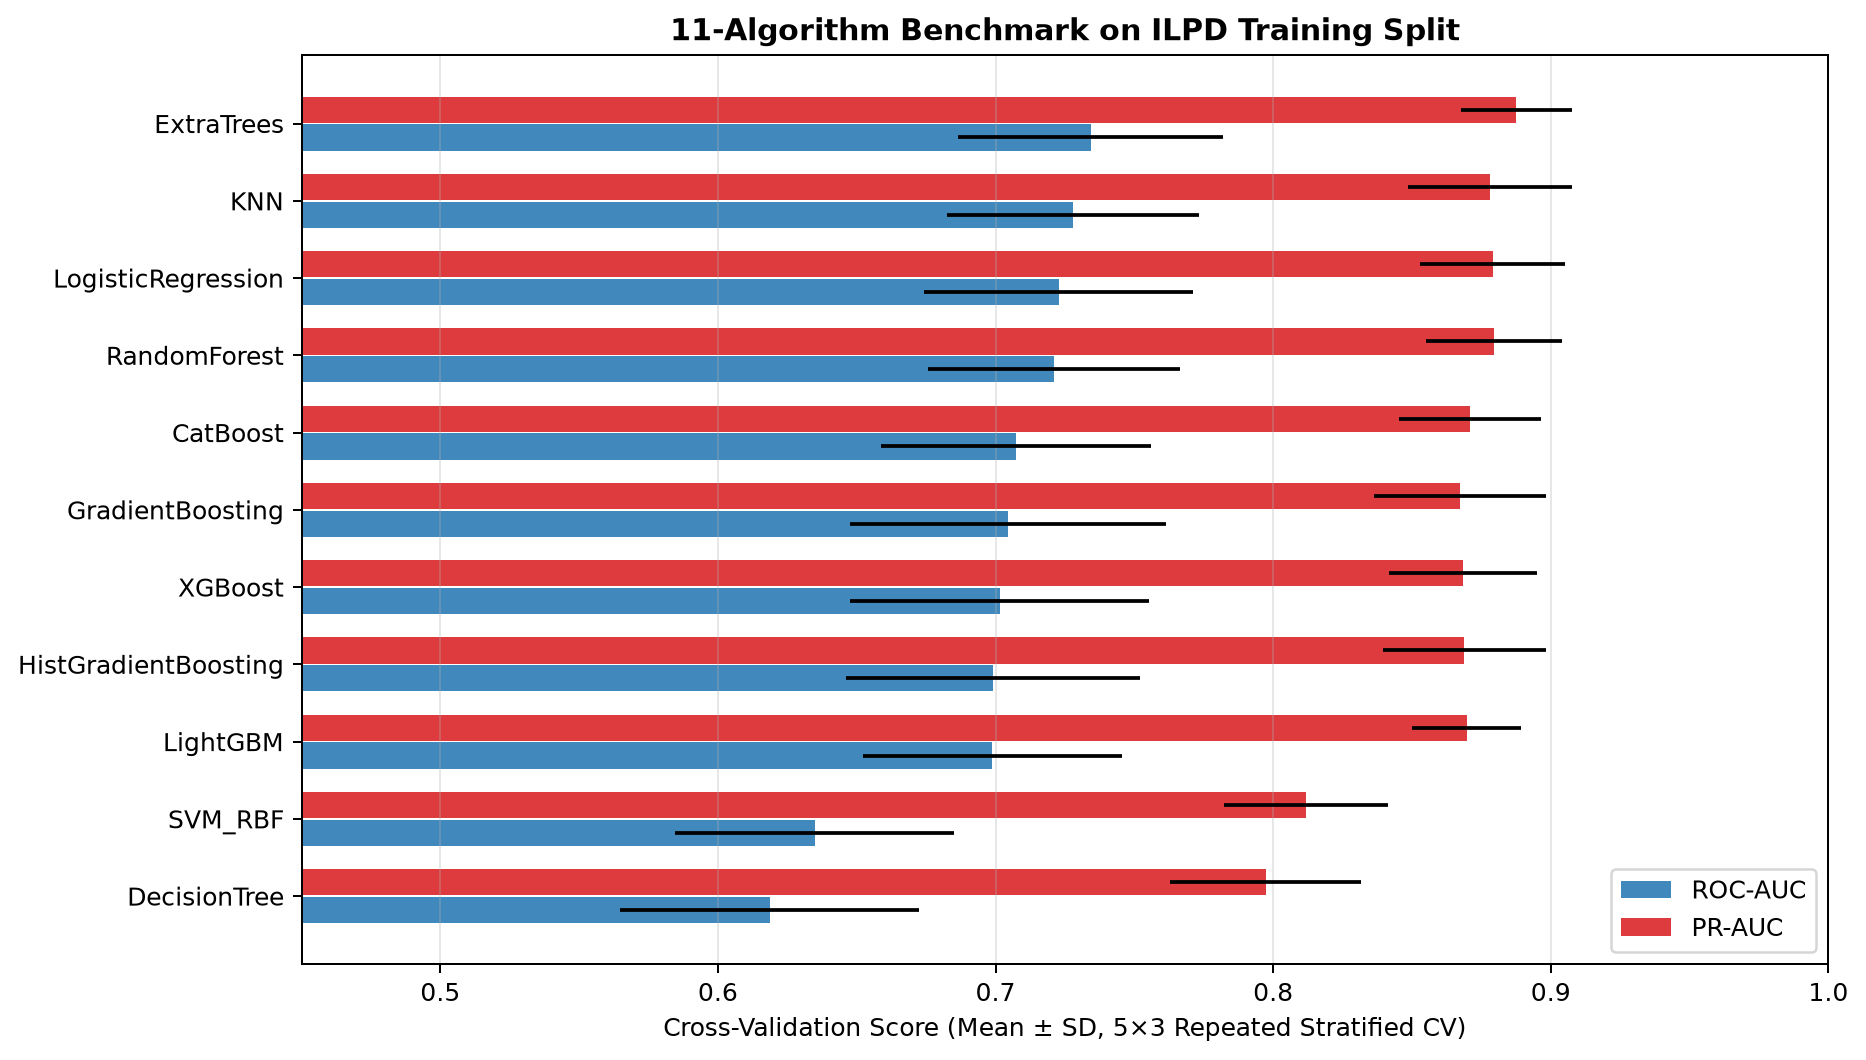

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
import pandas as pd
import numpy as np
from IPython.display import display, Image
from liver_disease.config import FIGURES_DIR, REPORTS_DIR

df_base = pd.read_csv(REPORTS_DIR / 'benchmark_11_models_baseline.csv')
print('=== Experiment 1: 11-Model Baseline Comparison ===')
display(df_base[['model', 'roc_auc_mean', 'roc_auc_std', 'pr_auc_mean', 'f1_score_mean', 'recall_sensitivity_mean', 'specificity_mean', 'balanced_accuracy_mean', 'brier_score_mean']])
display(Image(filename=str(FIGURES_DIR / '05_model_benchmark_comparison.png')))

In [2]:
df_fe = pd.read_csv(REPORTS_DIR / 'benchmark_feature_engineering_ablation.csv')
print('=== Experiment 2: Feature Engineering Ablation ===')
display(df_fe.groupby('feature_set')[['roc_auc_mean', 'pr_auc_mean', 'balanced_accuracy_mean', 'brier_score_mean']].mean().round(4))

df_imb = pd.read_csv(REPORTS_DIR / 'benchmark_imbalance_strategies.csv')
print('=== Experiment 3: Class Imbalance Strategy Comparison (In-Fold Only) ===')
display(df_imb.groupby('imbalance_strategy')[['roc_auc_mean', 'pr_auc_mean', 'recall_sensitivity_mean', 'specificity_mean', 'balanced_accuracy_mean', 'f1_score_mean']].mean().round(4))

df_fs = pd.read_csv(REPORTS_DIR / 'benchmark_feature_selection.csv')
print('=== Experiment 4: Mutual-Information Feature Selection Ablation ===')
display(df_fs[['model', 'k_features', 'roc_auc_mean', 'pr_auc_mean', 'balanced_accuracy_mean']])

=== Experiment 2: Feature Engineering Ablation ===


,roc_auc_mean,pr_auc_mean,balanced_accuracy_mean,brier_score_mean
feature_set,,,,
log1p_only,0.7041,0.8658,0.5486,0.1875
log1p_plus_clinical_ratios,0.7048,0.8636,0.5474,0.1863
raw_only,0.7011,0.8678,0.5457,0.1878


=== Experiment 3: Class Imbalance Strategy Comparison (In-Fold Only) ===


,roc_auc_mean,pr_auc_mean,recall_sensitivity_mean,specificity_mean,balanced_accuracy_mean,f1_score_mean
imbalance_strategy,,,,,,
class_weight,0.7154,0.8762,0.6990,0.5976,0.6483,0.7488
none,0.7143,0.8759,0.8675,0.2656,0.5666,0.8013
random_oversampler,0.7124,0.8750,0.7192,0.5517,0.6354,0.7550
smote,0.7144,0.8731,0.7130,0.5548,0.6339,0.7511


=== Experiment 4: Mutual-Information Feature Selection Ablation ===


,model,k_features,roc_auc_mean,pr_auc_mean,balanced_accuracy_mean
0,LogisticRegression,6,0.7197,0.8782,0.5460
1,LogisticRegression,8,0.7259,0.8797,0.5537
2,LogisticRegression,10,0.7228,0.8791,0.5611
3,LogisticRegression,all,0.7228,0.8791,0.5611
4,RandomForest,6,0.7062,0.8709,0.5632
5,RandomForest,8,0.7294,0.8837,0.5619
6,RandomForest,10,0.7211,0.8795,0.5687
7,RandomForest,all,0.7211,0.8795,0.5687
8,CatBoost,6,0.6999,0.8684,0.5641
9,CatBoost,8,0.7230,0.8798,0.5684
